In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [3]:
df = pd.read_csv("../data/student-por.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [4]:
def categorize_performance(g3):
    if g3 <= 9:
        return "Low"
    elif g3 <= 13:
        return "Average"
    else:
        return "Good"

df["performance_category"] = df["G3"].apply(categorize_performance)

print(df["performance_category"].value_counts())

performance_category
Average    355
Good       194
Low        100
Name: count, dtype: int64


In [5]:
X = df.drop(columns=["G1", "G2", "G3", "performance_category"])
y = df["performance_category"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (649, 30)
y shape: (649,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (519, 30)
X_test: (130, 30)
y_train: (519,)
y_test: (130,)


In [7]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 13
Categorical features: 17


In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (519, 56)
X_test_processed shape: (130, 56)


In [9]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print("y_train_encoded shape:", y_train_encoded.shape)
print("y_test_encoded shape:", y_test_encoded.shape)

Classes: ['Average' 'Good' 'Low']
y_train_encoded shape: (519,)
y_test_encoded shape: (130,)


In [10]:
# Compute class weights to handle class imbalance
from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_encoded),
    y=y_train_encoded
)

class_weights = dict(
    zip(np.unique(y_train_encoded), class_weights_array)
)

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.6091549295774648), np.int64(1): np.float64(1.1161290322580646), np.int64(2): np.float64(2.1625)}


In [11]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([
    Input(shape=(56,)),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.3),

    Dense(3, activation="softmax")
])

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,827 (22.76 KB)

 Trainable params: 5,827 (22.76 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [14]:
history = model.fit(
    X_train_processed,
    y_train_encoded,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.3904 - loss: 1.3017 - val_accuracy: 0.3942 - val_loss: 1.0602
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3470 - loss: 1.1305 - val_accuracy: 0.3942 - val_loss: 1.0860
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4048 - loss: 1.0758 - val_accuracy: 0.4808 - val_loss: 1.0553
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3976 - loss: 1.0768 - val_accuracy: 0.5288 - val_loss: 1.0404
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3952 - loss: 1.0449 - val_accuracy: 0.5288 - val_loss: 1.0203
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4241 - loss: 1.0163 - val_accuracy: 0.5288 - val_loss: 0.9987
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5060 - loss: 1.0075 - val_accuracy: 0.5385 - val_loss: 0.9816
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4747 - loss: 0.9990 - val_accuracy: 0.5481 - v

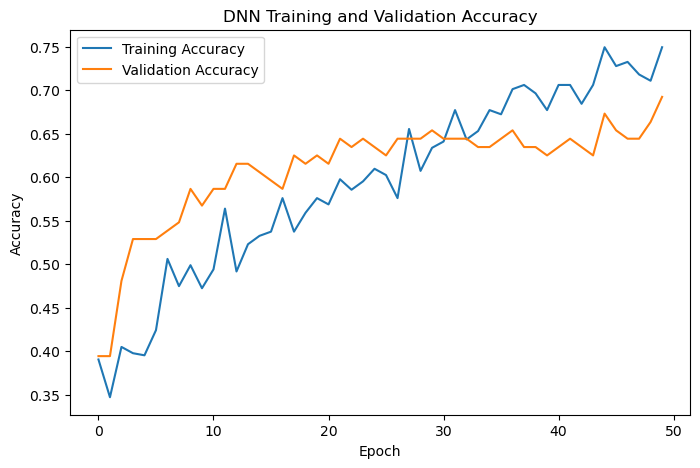

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("DNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

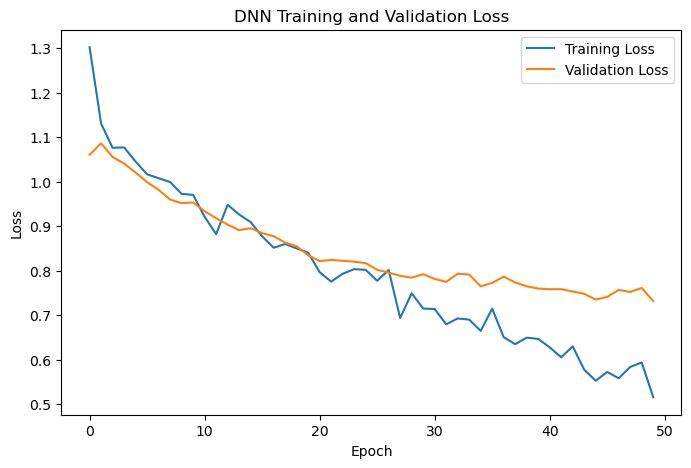

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("DNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [17]:
y_test_probabilities = model.predict(X_test_processed)

y_test_pred = np.argmax(
    y_test_probabilities,
    axis=1
)

print("Predictions generated successfully.")

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Predictions generated successfully.


In [18]:
print("First 10 predictions:", y_test_pred[:10])

First 10 predictions: [2 1 0 2 0 0 2 2 0 0]


In [19]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_test_pred,
    target_names=["Average", "Good", "Low"]
))

              precision    recall  f1-score   support

     Average       0.61      0.49      0.55        71
        Good       0.48      0.59      0.53        39
         Low       0.40      0.50      0.44        20

    accuracy                           0.52       130
   macro avg       0.50      0.53      0.51       130
weighted avg       0.54      0.52      0.53       130



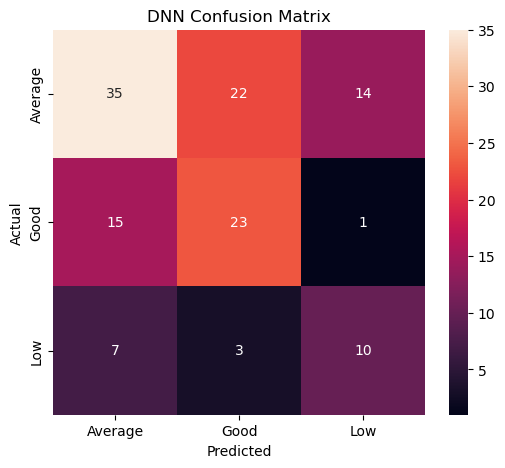

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_encoded,
    y_test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Average", "Good", "Low"],
    yticklabels=["Average", "Good", "Low"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DNN Confusion Matrix")
plt.show()